> **Plan** (what this sheet teaches; delete once the sections
> carry it on their own)
>
> A dat is a folder made from a spec, a recursive dict of
> parameters. Dat creation is three steps: look up the spec,
> expand it (merge its base, fill its `{}`), instantiate the Dat
> and its folder; each run by hand, the last producing the dat.
> Then `Dat.create`, the shorthand doing all three in one call. Then
> `Dat.manager.run`, the one way to run a dat, and `dat.run`, the
> record it leaves. Then a ledger: `L.at().run` is a run remembered, its
> spec the memo key, the same spec asked again found, not run; a
> dat sealed as a value; dats found by their preds.

#### Setup

In [1]:
import os, shutil, subprocess, sys, textwrap
from pathlib import Path

from IPython.display import SVG, display

from dvc_dat import Dat
from dvc_dat.ledger import Ledger

demos_path = Path(globals().get("demos_path", Path.cwd()))   # survives the chdir
os.chdir(demos_path)
scratch_path = demos_path / "scratch/q-dats"
shutil.rmtree(scratch_path, ignore_errors=True)   # a re-run starts clean
for module_name in [m for m in sys.modules if m.split(".")[0] == "mymodule"]:
    del sys.modules[module_name]
sys.path[:] = [p for p in sys.path if p != str(scratch_path)]

scratch_path.mkdir(parents=True)
os.chdir(scratch_path)
git_cmd = ["git", "-c", "user.name=demo", "-c", "user.email=demo@example.com"]
Path(".gitignore").write_text(".dat/\ndata/\n")
Path("pyproject.toml").write_text('[project]\nname = "q-dats"\nversion = "0.1.0"\n')
for args in (["init", "-q"], ["add", "."], ["commit", "-q", "-m", "q-dats"]):
    subprocess.run(git_cmd + args, check=True)
sys.path.insert(0, str(scratch_path))
Path(".datconfig.yaml").write_text("dat_folders: data\n")   # a plain dat project: its dats live in data/
Dat.manager = None                   # the dat world reloads from this folder


def show(name):
    """The figure `<name>.svg` beside this notebook."""
    display(SVG(filename=str(demos_path / f"{name}.svg")))

In [2]:
# the files: a run function in mult.py, two template specs in specs/
module_path = Path("mymodule")
(module_path / "specs").mkdir(parents=True)
(module_path / "__init__.py").write_text('__version__ = "0.1.0"\n')   # the code's version, in its source
(module_path / "mult.py").write_text('''\
import csv
from pathlib import Path


def write_table(folder, n=10, start=1):
    """`table.csv`, the n x n multiplication table from `start`; its cell count."""
    numbers = range(start, start + n)
    with open(Path(folder, "table.csv"), "w", newline="") as f:
        csv.writer(f).writerows([[a * b for b in numbers] for a in numbers])
    return n * n


def build_table(dat, n=10, start=1):
    """The run function: `Dat.manager.run` calls it with the new dat and the spec's kwargs."""
    cells = write_table(dat.get_path(), n, start)
    Path(dat.get_path(), "log.txt").write_text(f"{n} x {n} from {start}\\n")
    dat.get_results()["cells"] = cells
    dat.save()
    return dat
''')
(module_path / "specs/table_base.yaml").write_text('''\
dat:
  kwargs: {start: 1}
notes: shared defaults
''')
(module_path / "specs/table12.yaml").write_text('''\
dat:
  base: mymodule.specs.table_base
  name: tables/{YYYY}/table12{unique}
  do: mymodule.mult.build_table
  kwargs: {n: 12}
''')
subprocess.run(git_cmd + ["add", "mymodule"], check=True)
subprocess.run(git_cmd + ["commit", "-q", "-m", "mymodule"], check=True)
Dat.ns.mount(folder="mymodule", at="mymodule")   # mymodule's files join the dat world's namespace:
# mymodule/specs/table12.yaml answers to mymodule.specs.table12, build_table in mult.py to mymodule.mult.build_table



# Quick: dats

A dat is a handle for a folder of arbitrary data, derived from and
specified by a recursive dictionary of parameters: its spec. On a
ledger it is also a value: sealed, loaded, memoized, found.

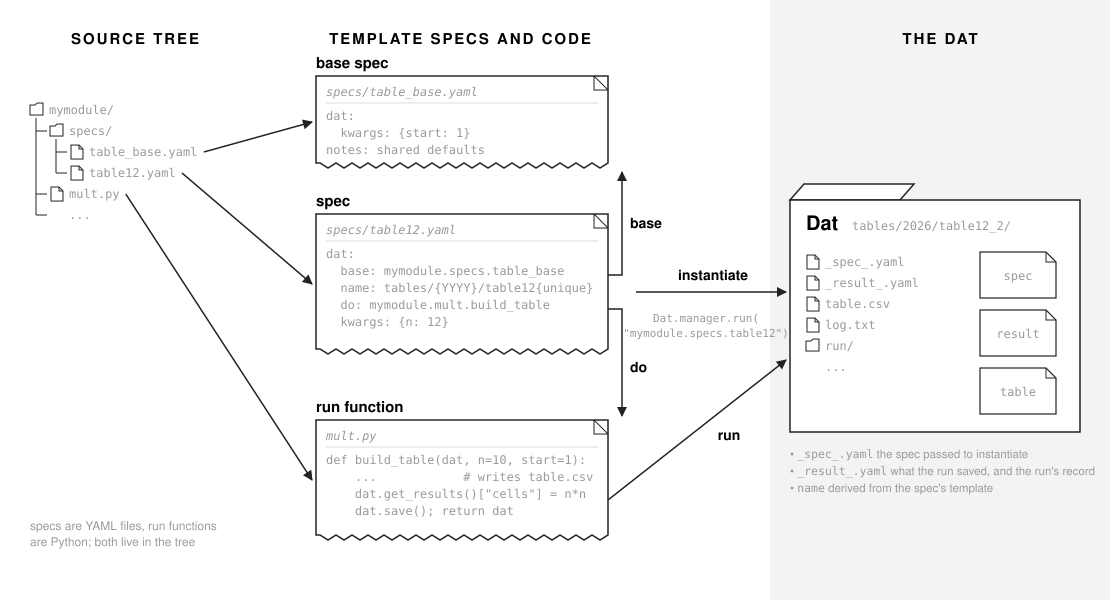

In [3]:
show("q-dats")

A spec's `dat:` part is what the dat system reads: `do:` names the
run function, `kwargs:` its arguments, `base:` a spec to inherit,
`name:` a folder template; Setup's `table12` inherits `table_base`.

## Dat creation

A dat is created in three steps:

1. **Look up** its spec by name: `Dat.ns.load(name)` is the object
   a dotted name names, here the spec file's dict as written.
2. **Expand** it: `Dat.manager.expand_spec(spec)` merges the spec
   over its `dat.base`, which it drops, then fills every template
   variable `{}`; `{YYYY}` is the year, `{unique}` empty.
3. **Instantiate** it: `Dat.create(spec=expanded_spec)` is the Dat
   object, its folder made and `_spec_.yaml` written. Nothing runs.

In [4]:
spec = Dat.ns.load("mymodule.specs.table12")    # 1. the spec as written
expanded_spec = Dat.manager.expand_spec(spec)   # 2. dat.base merged in, every {…} filled
table12_dat = Dat.create(spec=expanded_spec)    # 3. the Dat and its folder

In [5]:
# print results
table12_path = Path(table12_dat.get_path())
print("SPEC:    ", spec)
print("EXPANDED:", expanded_spec)   # base: gone, kwargs gains start, notes appears, name: filled
print("DAT:     ", repr(table12_dat))
print("FILES:   ", sorted(os.listdir(table12_path)))
print("_SPEC_.YAML:\n" + textwrap.indent((table12_path / "_spec_.yaml").read_text(), "    "))
# _spec_.yaml: the expanded spec, plus kind: dvc_dat.core.Dat

SPEC:     {'dat': {'base': 'mymodule.specs.table_base', 'name': 'tables/{YYYY}/table12{unique}', 'do': 'mymodule.mult.build_table', 'kwargs': {'n': 12}}}
EXPANDED: {'dat': {'kwargs': {'start': 1, 'n': 12}, 'name': 'tables/2026/table12', 'do': 'mymodule.mult.build_table'}, 'notes': 'shared defaults'}
DAT:      <Dat: tables/2026/table12>
FILES:    ['_spec_.yaml']
_SPEC_.YAML:
    dat:
      kwargs:
        start: 1
        n: 12
      name: tables/2026/table12
      do: mymodule.mult.build_table
      kind: dvc_dat.core.Dat
    notes: shared defaults



## `Dat.create`, the three steps in one call

`Dat.create(spec=name)` is the shorthand: it looks the spec up,
expands it (base merged, `{}` filled) and instantiates the dat.
Nothing runs.

In [6]:
shorthand_dat = Dat.create(spec="mymodule.specs.table12")   # steps 1-3

In [7]:
# print results
shorthand_path = Path(shorthand_dat.get_path())
print("DAT:", repr(shorthand_dat))
print("MANUAL _SPEC_.YAML:\n" + textwrap.indent((table12_path / "_spec_.yaml").read_text(), "    "))
print("SHORTHAND _SPEC_.YAML:\n" + textwrap.indent((shorthand_path / "_spec_.yaml").read_text(), "    "))
# the same kwargs, do, kind and notes; name: tables/2026/table12 by hand, tables/{YYYY}/table12{unique} in the shorthand

DAT: <Dat: tables/2026/table12_2>
MANUAL _SPEC_.YAML:
    dat:
      kwargs:
        start: 1
        n: 12
      name: tables/2026/table12
      do: mymodule.mult.build_table
      kind: dvc_dat.core.Dat
    notes: shared defaults

SHORTHAND _SPEC_.YAML:
    dat:
      kwargs:
        start: 1
        n: 12
      name: tables/{YYYY}/table12{unique}
      do: mymodule.mult.build_table
      kind: dvc_dat.core.Dat
    notes: shared defaults



One difference, in `name:`. The shorthand expands `{}` after it
places the folder, with the placement's own `{YYYY}` and `{unique}`:
`table12` is taken, so `{unique}` counts up to `_2`, and
`_spec_.yaml` keeps `name:` as the template. By hand,
`expand_spec` sees no folder, so `{unique}` is always empty and
`name:` is filled once; were `tables/2026/table12` taken, step 3
would raise `FileExistsError` instead of counting up.

## Running a dat

`Dat.manager.run(dat)` is the one way to run a dat: it calls the
spec's run function with the dat and the spec's kwargs, in place,
and records the run in `dat.run`. `save()` in the run function
seals the folder, its results in `_result_.yaml`.
The cell runs once: a sealed dat refuses a second run, which
`RuntimeError: ... is sealed` reports.

In [8]:
Dat.manager.run(table12_dat)   # calls build_table in mult.py with this dat and n=12, start=1

<Dat: tables/2026/table12>

In [9]:
# print results
print("FILES:", sorted(os.listdir(table12_path)))
print("CELLS:", table12_dat.get_results()["cells"])
print("TABLE.CSV:\n" + textwrap.indent("\n".join((table12_path / "table.csv").read_text().splitlines()[:3]), "    "))
print("_RESULT_.YAML:\n" + textwrap.indent((table12_path / "_result_.yaml").read_text(), "    "))

FILES: ['_result_.yaml', '_spec_.yaml', 'log.txt', 'run', 'table.csv']
CELLS: 144
TABLE.CSV:
    1,2,3,4,5,6,7,8,9,10,11,12
    2,4,6,8,10,12,14,16,18,20,22,24
    3,6,9,12,15,18,21,24,27,30,33,36
_RESULT_.YAML:
    dat:
      dependencies: {}
      standing: referenceable
      hash: functional
      sha256: sha256:4a1f195a93d4863c561b129b857351dd40ae67df33d6a9cab8bfb2f575be36dc
    cells: 144



`dat.run` is the run's record, a sub-dat in the dat's `run/`
folder: when and where it ran, on which commit, how long it took
and the hash it sealed. It is outside the dat's own hash.

In [10]:
run_results = table12_dat.run.get_results()["dat"]
print("run:", repr(table12_dat.run))   # run: <Dat: tables/2026/table12/run>
print("run_at:", run_results["run_at"])   # run_at: when the run started
print("run_time:", run_results["run_time"])   # run_time: how long build_table took
print("code:", run_results["code"])   # code: the branch, commit and dirty flag of the checkout holding mult.py

run: <Dat: tables/2026/table12/run>
run_at: 2026-10-27 23:13:58
run_time: 00:00:00.002
code: {'branch': 'main', 'commit': 'ffd1dcb39e9d1e96c877ecf836534b361ed337d7', 'dirty': False}


Given a name, `Dat.manager.run` creates the dat from the spec
first: it returns what the run function returned, a new folder
every call.

In [11]:
again_dat = Dat.manager.run("mymodule.specs.table12")   # same as: Dat.manager.run(Dat.create(spec="mymodule.specs.table12"))
print("dat:", repr(again_dat))   # dat: <Dat: tables/2026/table12_3>
print("files:", sorted(os.listdir(again_dat.get_path())))
# files: ['_result_.yaml', '_spec_.yaml', 'log.txt', 'run', 'table.csv']

dat: <Dat: tables/2026/table12_3>
files: ['_result_.yaml', '_spec_.yaml', 'log.txt', 'run', 'table.csv']


## Running and storing a dat on the ledger

A ledger remembers: a run is a memo entry, found again rather than
rerun; a dat is a value, sealed under a name and loaded back; dats
are found by their preds.

`Ledger(create=True)` makes the ledger in this folder and adds
`ledger:` to `.datconfig.yaml`; the reloaded dat world names
through it. In a ledger project names come from the ledger's
mounts alone and `Dat.ns.mount` is refused, so `mymodule` is
mounted with `t.ns.mount`, which writes two `db/mount` rows; the
earlier mount went with the old world.

#### Setup

In [12]:
L = Ledger(create=True)              # .dat/ledger, and ledger: in .datconfig.yaml
Dat.manager = None                   # the dat world reloads, its namespace the ledger's
print(".datconfig.yaml:", Path(".datconfig.yaml").read_text().splitlines())
# → .datconfig.yaml: ['dat_folders: data', 'ledger: .dat/ledger']
import mymodule                      # discovery finds the checkout, the repo q-dats
with L.transaction(by="human:dan", why="mount mymodule") as t:
    t.ns.mount("mymodule", root="mymodule")   # the two db/mount rows: the folder, and the repo, by default this project's, q-dats
try:
    Dat.ns.mount(folder="mymodule", at="mymodule")
except TypeError as e:
    print("refused:", str(e).split(" (")[0])
# → refused: a ledger project names things through its db/mount rows

.datconfig.yaml: ['dat_folders: data', 'ledger: .dat/ledger']
refused: a ledger project names things through its db/mount rows


### Ledger run

`L.at().run(name)` is a run remembered on the ledger: the result
found if this code computed it before, else run and sealed as the
memo entry. One call creates the dat in the three steps, runs it,
and remembers it.

In [13]:
table12_value = L.at().run("mymodule.specs.table12")
print("ran:", repr(table12_value))   # ran: <Dat tables/2026/table12>: the spec's template, filled in the ledger's data folder

ran: <Dat tables/2026/table12>


#### What the run did, piece by piece

The run took the three creation steps, through the ledger's
mounts: `Dat.ns.load` read the spec off the mounted file, never
imported; `expand_spec` merged its base and filled its `{}`. The
expanded spec, `dat.name` removed and `dat.kind` set, is the memo
key, stored as the value's `db/keys`.

In [14]:
# print results
print("SPEC:    ", Dat.ns.load("mymodule.specs.table12"))
print("EXPANDED:", Dat.manager.expand_spec(Dat.ns.load("mymodule.specs.table12")))
print("DB/KEYS: ", L.at()[table12_value.subject, "db/keys"])   # the memo key

SPEC:     {'dat': {'base': 'mymodule.specs.table_base', 'name': 'tables/{YYYY}/table12{unique}', 'do': 'mymodule.mult.build_table', 'kwargs': {'n': 12}}}


EXPANDED: {'dat': {'kwargs': {'start': 1, 'n': 12}, 'name': 'tables/2026/table12', 'do': 'mymodule.mult.build_table'}, 'notes': 'shared defaults'}
DB/KEYS:  {'dat': {'do': 'mymodule.mult.build_table', 'kind': 'dvc_dat.core.Dat', 'kwargs': {'n': 12, 'start': 1}}, 'notes': 'shared defaults'}


The run function loads as an `Fn`, a ledger function: kind `dat`
(undecorated, run through a spec), sandboxed because it is
mounted. It ran in a sandboxed worker, its code the mounted files
it loaded; `db/fn` names it, and the first clean run wrote the
package's version clock, `db/repo/q-dats/mymodule` `db/version`.

In [15]:
# print results
run_fn = Dat.ns.load("mymodule.mult.build_table")
print("FN:         ", repr(run_fn), " kind:", run_fn.kind, " sandboxed:", run_fn.code.sandboxed)
print("DB/FN:      ", L.at()[table12_value.subject, "db/fn"])
print("DB/VERSION: ", L.at()["db/repo/q-dats/mymodule", "db/version"])   # db/repo/q-dats/mymodule

FN:          <Fn mymodule.mult.build_table@0.1.0>  kind: dat  sandboxed: True
DB/FN:       mymodule.mult.build_table
DB/VERSION:  0.1.0


The same spec asked again is a memo hit: nothing runs, nothing is
written.

In [16]:
top_id = L.at().id
again_value = L.at().run("mymodule.specs.table12")
print("hit:", again_value.subject == table12_value.subject,
      " nothing written:", L.at().id == top_id)   # hit: True  nothing written: True

hit: True  nothing written: True


### Storing a handmade dat on the ledger

On a ledger a dat is a value: sealed under a name, loaded back,
found by its preds. The hand-made `table12_dat` is sealed here; nothing
runs. Its preds are its spec's `kwargs` and its result's entries,
read from the folder.

In [17]:
with L.transaction(by="human:dan") as t:
    table12_dat.seal(t, name="table/12")   # the folder's files go to the art store; the row names the kind, dvc_dat.core.Dat
print("dat:", repr(table12_dat), " sealed:", table12_dat.sealed)   # dat: <Dat table/12>  sealed: <the seal's moment>

loaded_dat = L.at().load("table/12")       # the folder rebuilt from the store; nothing runs
print("files:", sorted(os.listdir(loaded_dat.get_path())))
# files: ['_result_.yaml', '_spec_.yaml', 'log.txt', 'run', 'table.csv']
print("cells:", loaded_dat.get_results()["cells"])   # cells: 144
print("preds:", dict(sorted(loaded_dat.preds.items())))
# preds: {'cells': '144', 'n': '12', 'start': '1'}

dat: <Dat table/12>  sealed: 2026-10-28T06:14:03Z
files: ['_result_.yaml', '_spec_.yaml', 'log.txt', 'run', 'table.csv']
cells: 144
preds: {'cells': '144', 'n': '12', 'start': '1'}


Sealing sent the files to the art store by their hashes; the
manifest naming them is the value's bytes. `load` rebuilds the
folder from the store, a view in the ledger's data folder; it does
not run anything.

### Finding dats

A dat on the ledger is found by its preds: its spec's kwargs and
its results. `values(kind=Dat, **preds)` is every dat whose preds
equal the given ones; `value(...)` the one dat, an error on none
or several; `select(keys, ...)` the matches as tuples of the
named preds. First, two more runs, n=5 and n=9, to find among.

In [18]:
for n in (5, 9):
    L.at().run("mymodule.specs.table12", n=n)   # kwargs update the spec's dat.kwargs, as with Dat.manager.run

In [19]:
# print results
print("ALL:     ", L.at().values(kind=Dat))
print("N=12:    ", L.at().values(kind=Dat, n=12))       # the run and the handmade table/12
print("CELLS=81:", repr(L.at().value(kind=Dat, cells=81)))   # exactly one: the n=9 run
print("N, CELLS:", L.at().select(("n", "cells"), kind=Dat))   # every dat, two preds each
print("N=5:     ", L.at().select(("cells",), kind=Dat, n=5))   # one pred of the n=5 dat

ALL:      [<Dat tables/2026/table12>, <Dat table/12>, <Dat tables/2026/table12_2>, <Dat tables/2026/table12_3>]
N=12:     [<Dat tables/2026/table12>, <Dat table/12>]
CELLS=81: <Dat tables/2026/table12_3>
N, CELLS: [('12', '144'), ('12', '144'), ('5', '25'), ('9', '81')]
N=5:      [('25',)]
